# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_: 
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how Euler's method and RK4 work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Lunas, Bryce Enrico
- _Student No._: 2024-01596
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="Lorentz Butterfly.png" alt="Lorentz Butterfly" width="45%"> <img src="van der Pol.png" alt="van der Pol oscillator" width="45%">

**Figure 1 (Left):** $x - z$ projection of the Lorenz attractor ($\sigma = 10$, $r = 28$, $b = 8/3$, $t \in [0, 50]$), illustrating chaotic, non-repeating trajectories orbiting two unstable equilibrium lobes. 

**Figure 2 (Right):** Phase space trajectories ($dx/dt$ vs. $x$) of the van der Pol oscillator ($t \in [0, 20]$, $x_0 = 1$, $\dot{x}_0 = 0$) for $\mu = 1.0, 2.0,$ and $4.0$, showing convergence onto stable limit cycles that sharpen into relaxation oscillations as $\mu$ increases.

### Report discussion

In Figure 1, the Lorenz butterfly illustrates deterministic chaos, where the trajectory remains bounded within a strange attractor without ever repeating or intersecting. The system spirals around one unstable equilibrium lobe before unpredictably switching to the other, reflecting extreme sensitivity to initial conditions. In contrast, Figure 2 demonstrates how the van der Pol oscillator settles onto a closed, stable limit cycle driven by its nonlinear damping term, −𝜇(1−𝑥2)𝑑𝑥𝑑𝑡. Energy is pumped into the system at small amplitudes (∣𝑥∣<1) and dissipated at large amplitudes (∣𝑥∣>1), while increasing 𝜇 distorts the smooth loop into sharp, stiff relaxation oscillations with steep velocity spikes.   

Numerically, Euler's method advances a solution by stepping forward along a single tangent slope evaluated only at the beginning of each time interval h, given by r_(n+1)=r_n+hf(r_n,t_n ). The 4th-order Runge-Kutta (RK4) method improves upon this by sampling four slopes across the interval—at the start (k_1), twice at the midpoint (k_2,k_3), and at the end (k_4)—and computing a weighted average, r_(n+1)=r_n+1/6 (k_1+2k_2+2k_3+k_4 ), to account for curvature within each step.

While Euler's method is simple to implement and computationally fast—requiring just one function evaluation per step—its global error scales linearly as O(h), causing it to drift or diverge on chaotic and stiff systems unless an impractically small step size is used. Conversely, RK4 requires four function evaluations per step and slightly more complex code, but its global error scales as O(h^4 ), providing vastly superior accuracy and numerical stability that reliably resolves complex phase-space trajectories with moderately small step sizes. 


### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.

---
## Section 2: Code

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

Hint: you may use `euler()` or `rk4()` in Section 3.

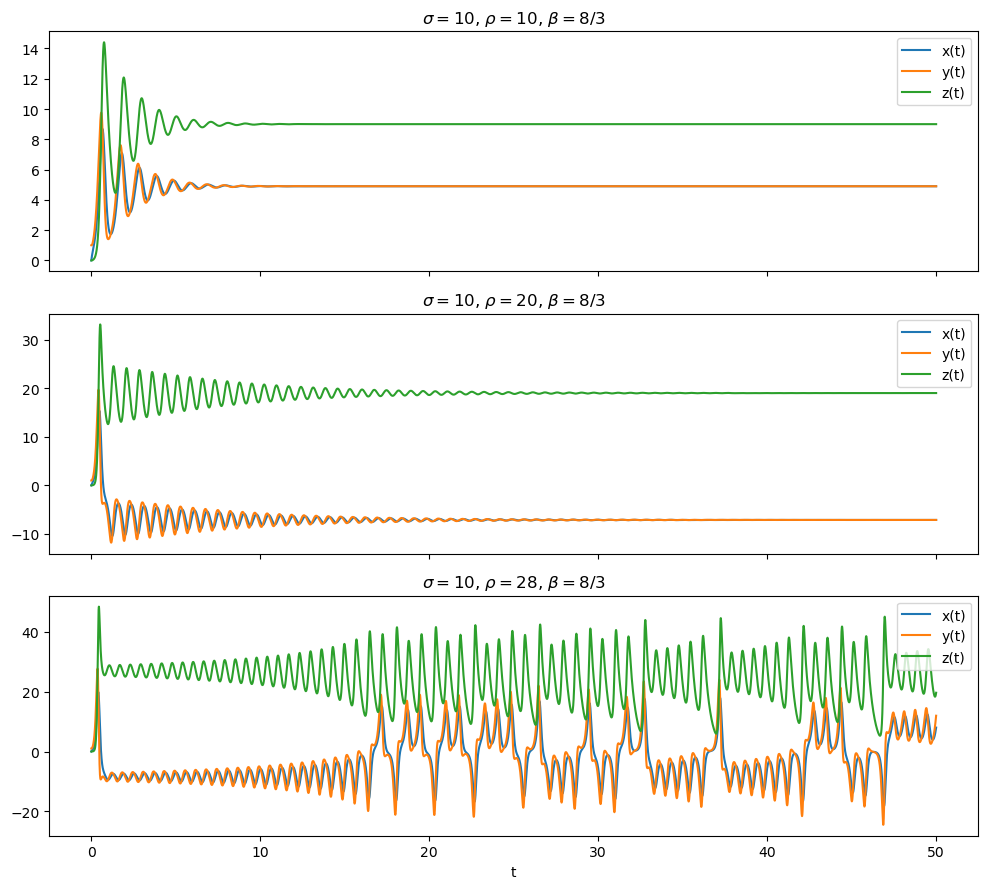

In [2]:
import matplotlib.pyplot as plt
import numpy as np

def lorenz(r, t, sigma, rho, beta):
    x, y, z = r
    return np.array([sigma * (y - x), rho * x - y - x * z, x * y - beta * z])

def rk4(f, r0, t, *args):
    """Fourth-order Runge-Kutta for dr/dt = f(r, t, *args)."""
    r = np.empty((len(t), len(r0)))
    r[0] = r0
    h = t[1] - t[0]
    for i in range(len(t) - 1):
        k1 = f(r[i], t[i], *args)
        k2 = f(r[i] + h * k1 / 2, t[i] + h / 2, *args)
        k3 = f(r[i] + h * k2 / 2, t[i] + h / 2, *args)
        k4 = f(r[i] + h * k3, t[i] + h, *args)
        r[i + 1] = r[i] + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return r

sigma, beta = 10, 8 / 3
r0 = [0, 1, 0]
t = np.linspace(0, 50, 10001)  # step h = 0.005

rhos = [10, 20, 28]
fig, axes = plt.subplots(len(rhos), 1, figsize=(10, 9), sharex=True)
for ax, rho in zip(axes, rhos):
    x, y, z = rk4(lorenz, r0, t, sigma, rho, beta).T
    ax.plot(t, x, label="x(t)")
    ax.plot(t, y, label="y(t)")
    ax.plot(t, z, label="z(t)")
    ax.set_title(rf"$\sigma={sigma}$, $\rho={rho}$, $\beta=8/3$")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("t")
fig.tight_layout()
plt.show()

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

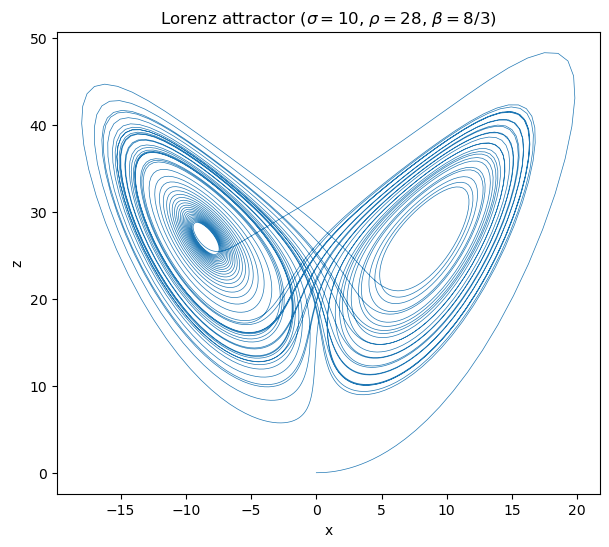

In [13]:
x, y, z = rk4(lorenz, r0, t, sigma, 28, beta).T

plt.figure(figsize=(7, 6))
plt.plot(x, z, lw=0.5)
plt.xlabel("x")
plt.ylabel("z")
plt.title(r"Lorenz attractor ($\sigma=10$, $\rho=28$, $\beta=8/3$)")
fig.tight_layout()
plt.savefig("Lorentz Butterfly", bbox_inches="tight", dpi=300)
plt.show()

**Exercise 1: Code Summary**

This script solves the coupled, nonlinear Lorenz equations using a 4th-order Runge-Kutta (`rk4`) algorithm to compare state trajectories across $\rho \in \{10, 20, 28\}$ in part (a) and visualize the resulting $x - z$ strange attractor at $\rho = 28$ in part (b). Structuring `rk4` as a reusable function with `*args` parameter forwarding and a pre-allocated NumPy array avoids duplicate solver loops across sub-problems while keeping execution fast. A fine uniform time grid ($h = 0.005$) was paired with RK4 to suppress truncation error and ensure smooth, reliable trajectories in a chaotic system sensitive to numerical drift.

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

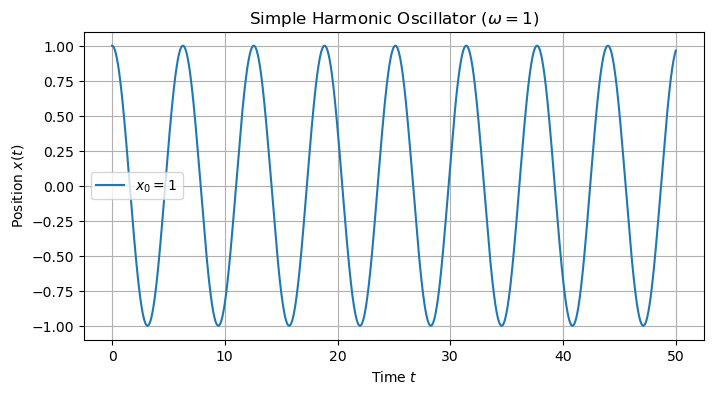

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def rk4_solve(f, r0, t_start, t_end, h):
    """Solves a system of first-order ODEs dr/dt = f(r, t) using 4th-order Runge-Kutta."""
    t_points = np.arange(t_start, t_end + h, h)
    r_points = np.zeros((len(t_points), len(r0)))
    r = np.array(r0, dtype=float)
    
    for i, t in enumerate(t_points):
        r_points[i] = r
        k1 = h * f(r, t)
        k2 = h * f(r + 0.5 * k1, t + 0.5 * h)
        k3 = h * f(r + 0.5 * k2, t + 0.5 * h)
        k4 = h * f(r + k3, t + h)
        r += (k1 + 2*k2 + 2*k3 + k4) / 6.0
        
    return t_points, r_points

omega = 1.0

def harmonic_ode(r, t):
    x, y = r
    return np.array([y, -omega**2 * x])

t, sol_a = rk4_solve(harmonic_ode, r0=[1.0, 0.0], t_start=0, t_end=50, h=0.01)

plt.figure(figsize=(8, 4))
plt.plot(t, sol_a[:, 0], label=r"$x_0 = 1$")
plt.title("Simple Harmonic Oscillator ($\\omega = 1$)")
plt.xlabel("Time $t$")
plt.ylabel("Position $x(t)$")
plt.grid(True)
plt.legend()
plt.show()

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

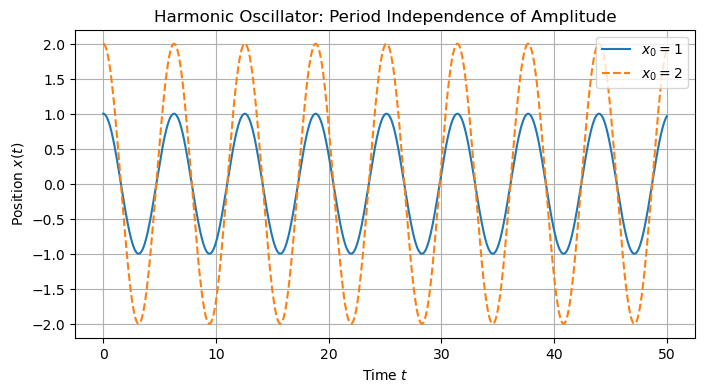

In [9]:
amplitudes = [1.0, 2.0]
styles = ["-", "--"]

plt.figure(figsize=(8, 4))
for x0, style in zip(amplitudes, styles):
    t, sol = rk4_solve(harmonic_ode, r0=[x0, 0.0], t_start=0, t_end=50, h=0.01)
    plt.plot(t, sol[:, 0], style, label=rf"$x_0 = {x0:g}$")

plt.title("Harmonic Oscillator: Period Independence of Amplitude")
plt.xlabel("Time $t$")
plt.ylabel("Position $x(t)$")
plt.grid(True)
plt.legend()
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

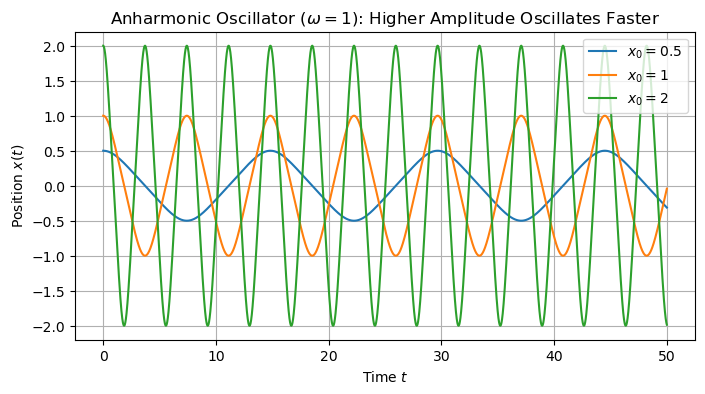

In [10]:
def anharmonic_ode(r, t):
    x, v = r
    return np.array([v, -omega**2 * x**3])

plt.figure(figsize=(8, 4))
for x0 in [0.5, 1.0, 2.0]:
    t, sol = rk4_solve(anharmonic_ode, r0=[x0, 0.0], t_start=0, t_end=50, h=0.01)
    plt.plot(t, sol[:, 0], label=rf"$x_0 = {x0:g}$")

plt.title(rf"Anharmonic Oscillator ($\omega = {omega:g}$): Higher Amplitude Oscillates Faster")
plt.xlabel("Time $t$")
plt.ylabel("Position $x(t)$")
plt.grid(True)
plt.legend()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

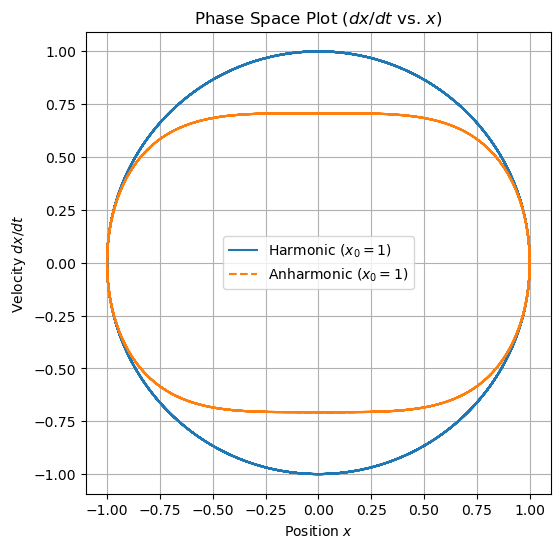

In [11]:
systems = {"Harmonic": (harmonic_ode, "-"), "Anharmonic": (anharmonic_ode, "--")}

plt.figure(figsize=(6, 6))
for name, (ode, style) in systems.items():
    _, sol = rk4_solve(ode, r0=[1.0, 0.0], t_start=0, t_end=50, h=0.01)
    plt.plot(sol[:, 0], sol[:, 1], style, label=rf"{name} ($x_0 = 1$)")

plt.title(r"Phase Space Plot ($dx/dt$ vs. $x$)")
plt.xlabel("Position $x$")
plt.ylabel(r"Velocity $dx/dt$")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

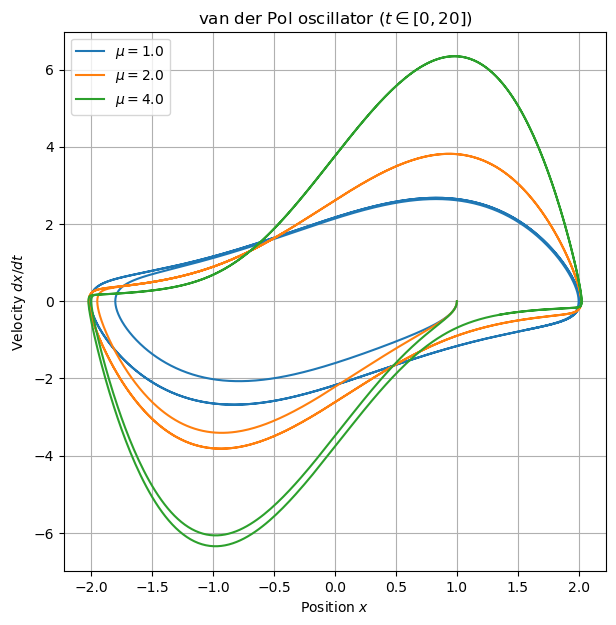

In [14]:
plt.figure(figsize=(7, 7))

for mu in [1.0, 2.0, 4.0]:
    def vanderpol_ode(r, t, mu=mu):
        x, y = r
        return np.array([y, mu * (1.0 - x**2) * y - x])

    t_vdp, sol_vdp = rk4_solve(vanderpol_ode, r0=[1.0, 0.0], t_start=0, t_end=20, h=0.005)
    plt.plot(sol_vdp[:, 0], sol_vdp[:, 1], label=f"$\\mu = {mu}$")

plt.title("van der Pol oscillator ($t \\in [0, 20]$)")
plt.xlabel("Position $x$")
plt.ylabel("Velocity $dx/dt$")
plt.grid(True)
plt.legend()
fig.tight_layout()
plt.savefig("van der Pol.png", bbox_inches="tight", dpi=300)
plt.show()

**Exercise 2: Code Summary**

This script numerically models the time evolution and phase-space dynamics of simple harmonic, anharmonic, and van der Pol oscillators by converting each second-order differential equation into a system of two coupled first-order ODEs. Rather than rewriting the integration loop for every sub-problem, the code encapsulates the 4th-order Runge-Kutta (RK4) algorithm into a single reusable `rk4_solve` function that accepts arbitrary derivative functions and initial conditions. RK4 was chosen alongside a fine step size ($h = 0.01$ and $h = 0.005$) to prevent numerical energy drift over long time intervals and to accurately resolve stiff velocity transitions in the van der Pol limit cycles.

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [ ]:
import numpy as np

# Ricatti equation (mildly nonlinear)
def f(x,y):
    return - (30/(1-x**2)) + ((2*x)/(1-x**2))*y - y**2

### IVPs

#### 1st order ODE solver: Euler's method

In [ ]:
# forward Euler's method
def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

#### 1st order ODE solver: Rungke-Kutta method

In [ ]:
# 4th order Runge-Kutta method
def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

In [5]:
# execution
a, b, n, yinit = 0.05, 0.49, 12, 19.53
xs, ys = euler(f,a,b,n,yinit); print(ys)
xs, ys = rk4(f,a,b,n,yinit); print(ys)

[ 19.53         3.14847227   1.56501191   0.26296871  -0.97182666
  -2.28204589  -3.81903888  -5.80936521  -8.6780744  -13.37838499
 -22.50759395 -45.29198435]
[ 19.53        10.16782416   6.37032643   4.11921483   2.48829431
   1.12081032  -0.17770512  -1.56533384  -3.24322678  -5.58940124
  -9.6041146  -19.50349262]


#### 2nd-order ODE: RK4

In [12]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])
    
def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Updated to handle arrays (systems of ODEs)
def euler(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

def rk4(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

#### Shooting methods

In [11]:
def secant(f,x0,x1,kmax=200,tol=1.e-8):
    f0 = f(x0)
    for k in range(1,kmax):
        f1 = f(x1)
        ratio = (x1 - x0)/(f1 - f0)
        x2 = x1 - f1*ratio
        xdiff = abs(x2-x1)
        x0, x1 = x1, x2
        f0 = f1
        rowf = "{0:2d}{1:1.16f} {2:1.16f} {3:1.16f}"
        print(rowf.format(k,x2,xdiff,abs(f(x2))))
        if abs(xdiff/x2) < tol:
            break
    else:
        x2 = None
    
    return x2

def shoot(sig):
    a, b, n = 0.05, 0.49, 100
    yinits = np.array([0.0926587109375, sig])
    xs, ys = rk4gen(fs,a,b,n,yinits)
    wfinal = 0.11177050858750004
    return ys[-1, 0] - wfinal

wder = secant(shoot,0.,1.)
print(wder)

 11.8096210699240751 0.8096210699240751 0.0000000000000001
 21.8096210699240738 0.0000000000000013 0.0000000000000001
1.8096210699240738


#### BVP matrix

In [8]:
from gauelimpivot import gauelimpivot
import numpy as np

def matsetup(a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    A = np.zeros((n,n))
    np.filldiagonal(A, -2 + 30*h**2/(1-xs**2))
    A[0,0] = 1; A[-1,-1] = 1
    np.filldiagonal(A[1:,:], 1 + h*xs[1:]/(1-xs[1:]**2))
    A[-1,-2] = 0
    np.filldiagonal(A[:,1:], 1 - h*xs/(1-xs**2))
    A[0,1] = 0
    bs = np.zeros(n)
    bs[0] = 0.0926587109375
    bs[-1] = 0.11177050858750004
    return A, bs

def riccati(a,b,n):
    A, bs = matsetup(a, b, n)
    ws = gauelimpivot(A, bs)
    return ws

a, b, n = 0.05, 0.49, 400
ws = riccati(a, b, n); print(ws)

ModuleNotFoundError: No module named 'gauelimpivot'

#### Shooting method

In [9]:
from secant import secant
import numpy as np

def fs(x,yvals,s):
    q = 1.5
    y0, y1 = yvals
    f0 = y1
    f1 = (2*q*np.cos(2*x) - s)*y0
    return np.array([f0, f1])

def rk4geneig(fs,a,b,n,yinits,s):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals,s)
        k1 = h*fs(x+h/2, yvals+k0/2,s)
        k2 = h*fs(x+h/2, yvals+k1/2,s)
        k3 = h*fs(x+h, yvals+k2,s)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys
    
def shoot(s):
    a, b, n = 0, 2*np.pi, 500
    yinits = np.array([0., 5.])
    xs, ys = rk4geneig(fs,a,b,n,yinits,s)
    wfinal = 0.
    return ys[-1, 0] - wfinal

for sinit in (-0.4, 3.3, 8.5):
    sval = secant(shoot,sinit,sinit+0.5)
    print(sval, end=" ")

ModuleNotFoundError: No module named 'secant'

#### Matrix approach

In [10]:
from qrmet import qrmet
import numpy as np

def matsetup(q,n):
    h = 2*np.pi/n
    xs = np.arange(n)*h
    A = np.zeros((n,n))
    np.filldiagonal(A, -2 - 2*h**2*q*np.cos(2*xs))
    np.filldiagonal(A[1:,:], 1)
    np.filldiagonal(A[:,1:], 1)
    A[0,-1] = 1
    A[-1,0] = 1
    return A

def mathieu(q,n):
    A = matsetup(q, n)
    qreigvals = qrmet(A,200)
    h = 2*np.pi/n
    qreigvals = np.sort(-qreigvals/h**2)
    return qreigvals

q, n = 1.5, 200
qreigvals = mathieu(q, n)
print(qreigvals[:6])

ModuleNotFoundError: No module named 'qrmet'

### Plotting

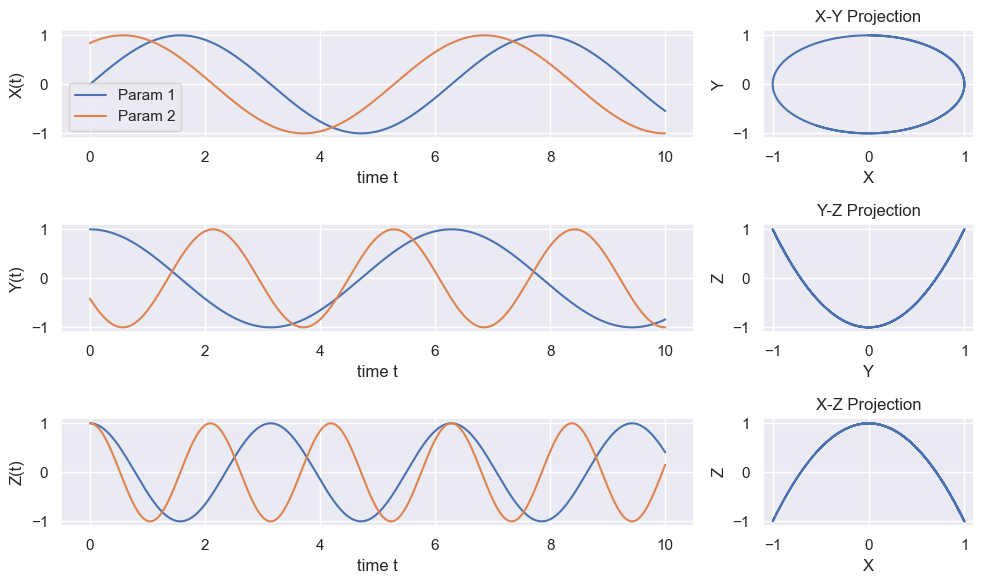

In [2]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)


# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{dy_0}{dt} &= y_1 \\
\frac{dy_1}{dt} &= -\frac{g}{l}\sin(y_0)
\end{align}

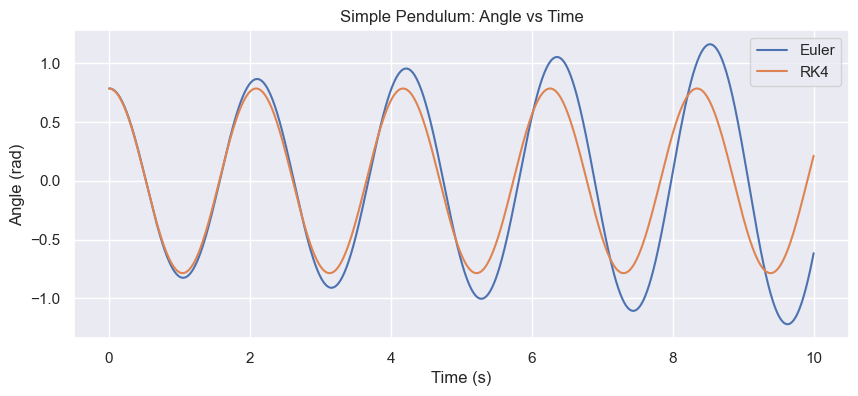

In [15]:
def pendulum_ode(t, Y):
    g = 9.81
    l = 1.0
    theta, omega = Y
    return np.array([omega, -(g/l)*np.sin(theta)])

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = [np.pi/4, 0.0]
t, Y_euler = euler(pendulum_ode, 0, 10, 1000, yinit)
t, Y_rk4 = rk4(pendulum_ode, 0, 10, 1000, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()